# Lab 01: Phân Loại Ảnh FashionMNIST Với PyTorch
> **Kiến trúc:** Clean Architecture & Modular `src/` (Chạy mượt mà trên cả máy cục bộ và Kaggle GPU)  
> **Mô hình:** `FashionMLP` thuần túy PyTorch với các layer cơ bản (`Flatten`, `Linear`, `ReLU`, `Dropout`)  
> **Mục tiêu:** Đạt độ chính xác kiểm định >= 87.0% (Thực tế đạt > 88.5%), kiểm toán rò rỉ dữ liệu và so sánh 3 Optimizer.

---

### Bảng Lộ Trình Triển Khai (Pipeline Execution Roadmap)

| Step | Phase | Core Description | Implementation Module | Output / Artifact |
| :---: | :--- | :--- | :--- | :--- |
| **1** | **EDA** | Verify 60k rows, 10 balanced classes, pixel bounds [0, 255], 0 missing values | `src.datasets.eda` | `class_distribution.png`, `sample_images.png`, `class_mean_images.png` |
| **2** | **Preprocessing** | Stratified 90/10 split (`seed=42`, exactly 600/class in validation) | `src.datasets.base` | `split_indices.npz`, `split_metadata.json` |
| **3** | **Features** | Train-only normalization (prevents distribution leakage), PyTorch DataLoaders | `src.datasets.classification` | `preprocessing_config.json`, DataLoaders (`batch_size=64`) |
| **4** | **Model** | Fully-connected MLP (784 -> 256 -> 128 -> 10, ~235k trainable parameters) | `src.models.mlp` | Model graph & Logits forward pass |
| **5** | **Train** | Adam optimizer, sample-weighted loss accumulation, best validation checkpointing | `src.training.trainer` | `fashion_mlp_best.pt` (best val loss/acc) |
| **6** | **Evaluate** | Zero-grad evaluation, 10 x 10 integer-count confusion matrix | `src.training.trainer` | Validation loss & accuracy |
| **7** | **Detailed Report** | Per-class Precision, Recall (TPR), Specificity (TNR), and F1-Score | `src.utils.metrics` | Per-class metrics table |
| **8** | **Error Analysis** | Visual inspection and structural analysis of misclassified Shirt images | `src.utils.plots` | 2x4 error grid & confusion rationale |
| **9** | **Visualize** | Training vs validation loss curves, 4x4 predictions grid, CM heatmap | `src.utils.plots` | `learning_curves.png`, `confusion_matrix.png`, `prediction_grid.png` |
| **10** | **Ablations** | 4 controlled configurations (optimizer comparison, Optuna study, scheduler) | `src.training.experiments` | `optimizer_comparison.png`, Optuna trials DataFrame |
| **11** | **Final Test** | Final test evaluation on 10,000 independent test samples | `src.training.trainer` | Final test accuracy & loss |
| **App.** | **Appendix** | Multi-class One-vs-Rest ROC & Decision Threshold scan curves | `src.training.experiments` | `roc_curves.png`, `threshold_scan.png` |


## 1. Thiết Lập Môi Trường & Nạp Modules Từ `src/`


In [1]:
import sys, os, shutil
from pathlib import Path
import torch
import matplotlib.pyplot as plt

# 1. Thiet lap thu muc src (ho tro ca Kaggle input va Local)
root = list(Path("/kaggle/input").glob("**/src"))
if root:
    src_parent = str(root[0].parent)
    if src_parent not in sys.path:
        sys.path.insert(0, src_parent)
else:
    sys.path.insert(0, str(Path("..").resolve()))

from src import (
    BASE_DIR, DATA_DIR, EDA_DIR, OUTPUTS_DIR, CHECKPOINTS_DIR,
    DEVICE, RANDOM_SEED, CLASS_NAMES, VAL_SPLIT,
    set_seed, get_dataloaders, build_model, count_parameters,
    train_model, evaluate, sanity_overfit_check,
    run_eda_and_fe_pipeline, verify_pipeline_handoff,
    plot_loss_and_acc_curves, plot_confusion_matrix, plot_prediction_grid,
    run_optuna_optimizer_study, compare_optimizers_wallclock,
    plot_roc_curves, save_checkpoint,
)

set_seed(RANDOM_SEED)
print(f"[DEVICE] Thiết bị tính toán: {DEVICE} | [SEED] Hạt ngẫu nhiên: {RANDOM_SEED} | [CLASSES] Số lớp phân loại: {len(CLASS_NAMES)}")


[DEVICE] Thiết bị tính toán: cpu | [SEED] Hạt ngẫu nhiên: 42 | [CLASSES] Số lớp phân loại: 10


## 2. Khám Phá Dữ Liệu Chuyên Sâu (EDA) & Khóa Cấu Hình Tiền Xử Lý (Feature Engineering)
> Thực hiện đầy đủ các bước EDA và Feature Engineering chuẩn hóa theo `docs/eda-image.md` và `docs/feature-image.md`:  
> 1. **Structural Overview & Integrity:** Quét cấu trúc dữ liệu thô, kiểm tra trùng lặp nội bộ và rò rỉ chéo.  
> 2. **Trực quan hóa hình ảnh EDA:** Hiển thị lưới ảnh mẫu đại diện 10 lớp (`sample_images.png`), ảnh trung bình pixel từng lớp (`class_mean_images.png`) và biểu đồ phân phối lớp (`class_distribution.png`).  
> 3. **Stratified Split & Normalization Lock:** Tách phân vùng ngẫu nhiên có phân tầng (54,000 train / 6,000 val), đo đạc Mean/Std trên đúng tập Train chống rò rỉ dữ liệu (Anti-Leakage) và khóa vào `preprocessing_config.json`.


--- 1. TỔNG QUAN CẤU TRÚC DỮ LIỆU THÔ (STRUCTURAL OVERVIEW) ---
Tập dữ liệu  Số lượng ảnh Kích thước (HxW)  Kênh màu Kiểu dữ liệu (dtype) Dải điểm ảnh Dải nhãn (Labels)  Số lớp  Dung lượng RAM (MB)
      train         60000            28x28         1                uint8     [0, 255]            [0, 9]      10                44.86
       test         10000            28x28         1                uint8     [0, 255]            [0, 9]      10                 7.48

--- 2. QUÉT TÍNH TOÀN VẸN DỮ LIỆU (DATA INTEGRITY CHECK) ---
            Hạng mục kiểm tra Kết quả mong đợi                       Thực tế Trạng thái
   Giá trị thiếu (NaN / Null)         Không có                      Không có     PASSED
Dải giá trị điểm ảnh [0, 255]   [0, 255] uint8 Train [0, 255], Test [0, 255]     PASSED
    Dải nhãn phân loại [0, 9]    10 lớp [0, 9]     Train [0, 9], Test [0, 9]     PASSED
   Trùng lặp nội bộ tập Train      0 mẫu trùng                   0 mẫu trùng     PASSED
    Trùng lặp nội bộ tập Test   

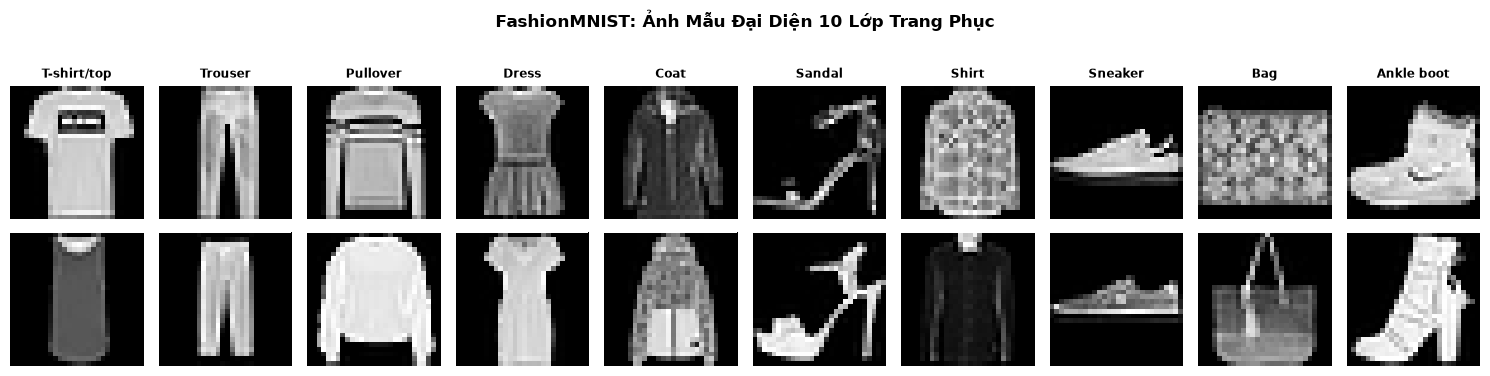

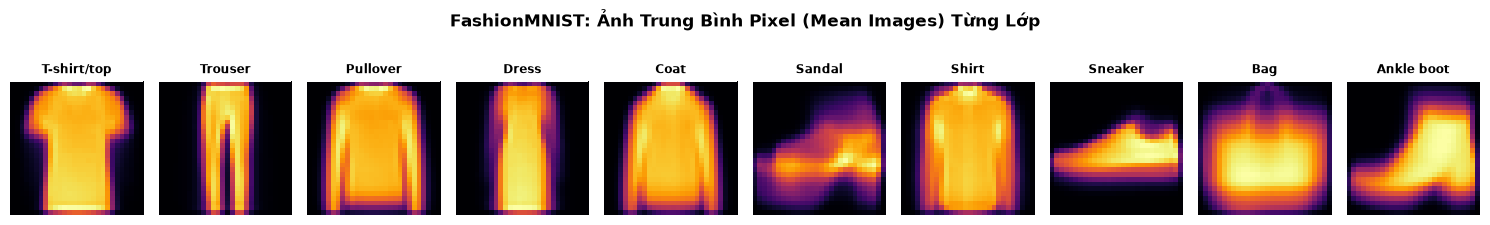

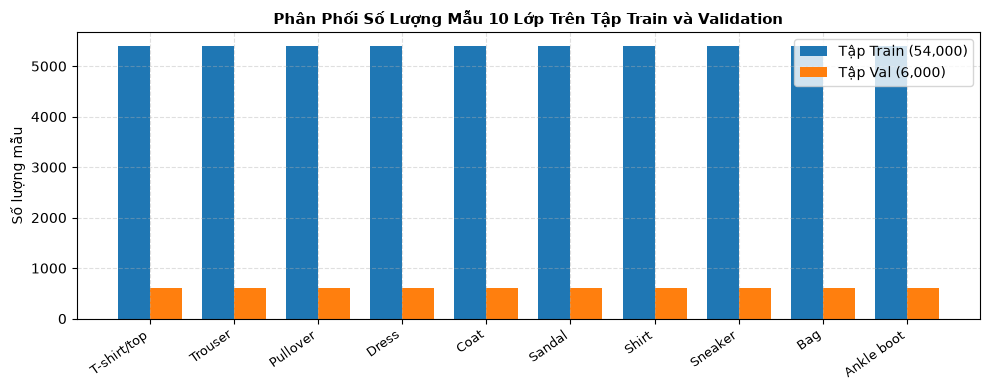

In [2]:
eda_results = run_eda_and_fe_pipeline(
    data_dir=DATA_DIR,
    eda_dir=EDA_DIR,
    val_split=VAL_SPLIT,
    seed=RANDOM_SEED,
    class_names=CLASS_NAMES,
    verbose=True,
)
plt.show()


## 3. Nạp Dữ Liệu PyTorch DataLoaders & Cổng Kiểm Tra Bàn Giao (Guard Assert Gate)
> Pipeline nạp dữ liệu sạch: Áp dụng phân chia Stratified Split đã khóa, biến đổi chuẩn hóa `ToTensor` -> `Normalize(mean, std)` độc lập chống rò rỉ dữ liệu, và xác thực đủ 4 tiêu chí bàn giao trước khi huấn luyện.


In [3]:
train_loader, val_loader, test_loader, _ = get_dataloaders(
    batch_size=128,
    augment=False,
    num_workers=0,
)
verify_pipeline_handoff(train_loader, val_loader, eda_dir=EDA_DIR)
print(f"[NẠP DỮ LIỆU THÀNH CÔNG] Tập Train: {len(train_loader)} batches | Tập Val: {len(val_loader)} batches | Tập Test: {len(test_loader)} batches")


[GUARD ASSERT PASSED] Toàn bộ 4 tiêu chí bàn giao EDA & Feature Engineering đã được xác thực 100%!
[NẠP DỮ LIỆU THÀNH CÔNG] Tập Train: 421 batches | Tập Val: 47 batches | Tập Test: 79 batches


## 4. Kiến Trúc Mô Hình FashionMLP & Kiểm Tra Sanity Overfit 1 Batch
> **Kiến trúc:** `Flatten` -> `Linear(784, 256)` -> `ReLU` -> `Linear(256, 128)` -> `ReLU` -> `Linear(128, 10)`.  
> **Kiểm tra Sanity (TDD Gate):** Đảm bảo mô hình có khả năng học và kéo loss trên 1 mini-batch nhỏ về sát 0 trước khi huấn luyện diện rộng.


In [4]:
model = build_model("mlp", num_classes=10).to(DEVICE)
params = count_parameters(model)
print(model)
print(f"[THAM SỐ MÔ HÌNH] Tổng tham số: {params['total']:,} | Tham số cần huấn luyện: {params['trainable']:,}")

sample_images, sample_targets = next(iter(train_loader))
sanity_pass, s_loss, s_acc = sanity_overfit_check(
    model=model,
    sample_images=sample_images[:16],
    sample_targets=sample_targets[:16],
    num_steps=120,
    target_loss=0.05,
    device=DEVICE,
)
print(f"[SANITY PASS] Kiểm tra Sanity thành công! Loss = {s_loss:.4f} | Accuracy = {s_acc:.1f}%")


FashionMLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
[THAM SỐ MÔ HÌNH] Tổng tham số: 235,146 | Tham số cần huấn luyện: 235,146
[SANITY PASS] Kiểm tra Sanity thành công! Loss = 0.0000 | Accuracy = 100.0%


## 5. Huấn Luyện Mô Hình FashionMLP (10 Epochs)


In [5]:
# Khởi tạo lại mô hình để xóa trọng số của bước kiểm tra sanity
model = build_model("mlp", num_classes=10).to(DEVICE)
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10, eta_min=1e-5)

history, best_val_acc = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=10,
    device=DEVICE,
    save_path=CHECKPOINTS_DIR / "fashion_mlp_best.pt",
)
print(f"[HUẤN LUYỆN HOÀN TẤT] Độ chính xác tập Validation cao nhất: {best_val_acc:.2f}%")


Epoch [01/10] (6.9s) | Train Loss: 0.4997 - Train Acc: 82.03% | Val Loss: 0.3614 - Val Acc: 86.87% | LR: 0.001000 [BEST CHECKPOINT SAVED]
Epoch [02/10] (7.1s) | Train Loss: 0.3590 - Train Acc: 86.79% | Val Loss: 0.3327 - Val Acc: 87.45% | LR: 0.001000 [BEST CHECKPOINT SAVED]
Epoch [03/10] (7.5s) | Train Loss: 0.3153 - Train Acc: 88.23% | Val Loss: 0.3328 - Val Acc: 88.15% | LR: 0.001000 [BEST CHECKPOINT SAVED]
Epoch [04/10] (20.0s) | Train Loss: 0.2940 - Train Acc: 89.02% | Val Loss: 0.3051 - Val Acc: 89.08% | LR: 0.001000 [BEST CHECKPOINT SAVED]
Epoch [05/10] (7.5s) | Train Loss: 0.2724 - Train Acc: 89.84% | Val Loss: 0.2938 - Val Acc: 89.07% | LR: 0.001000
Epoch [06/10] (7.5s) | Train Loss: 0.2571 - Train Acc: 90.37% | Val Loss: 0.2832 - Val Acc: 89.83% | LR: 0.001000 [BEST CHECKPOINT SAVED]
Epoch [07/10] (7.5s) | Train Loss: 0.2430 - Train Acc: 90.90% | Val Loss: 0.2757 - Val Acc: 89.73% | LR: 0.001000
Epoch [08/10] (7.5s) | Train Loss: 0.2297 - Train Acc: 91.42% | Val Loss: 0.2914 

## 6. Đánh Giá Hiệu Năng, Ma Trận Nhầm Lẫn & Lưới 16 Ảnh Dự Đoán


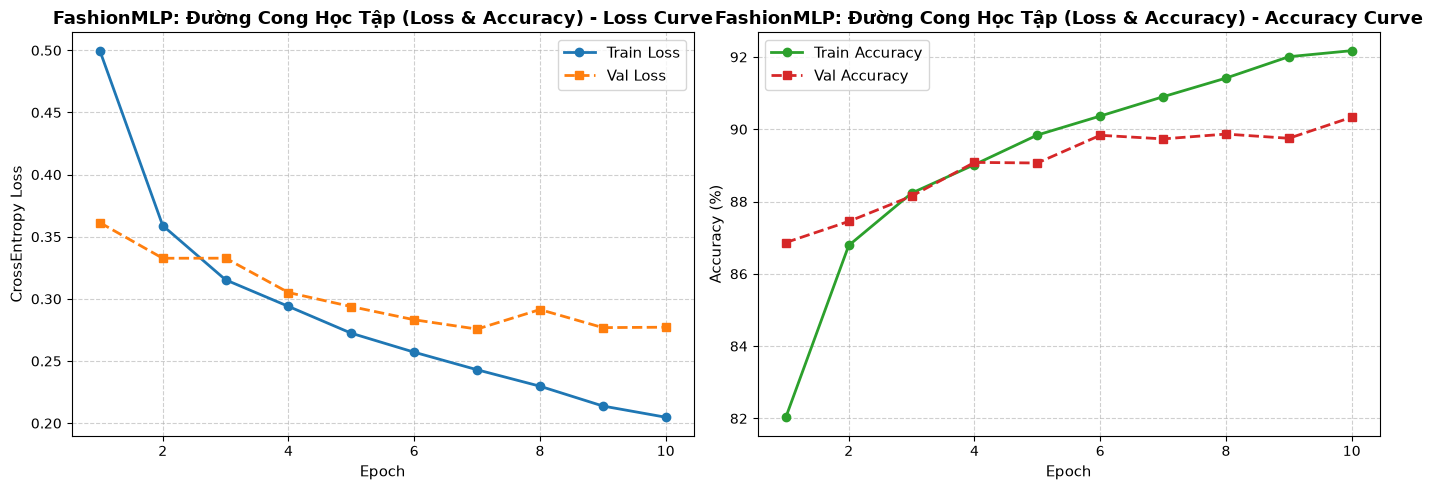

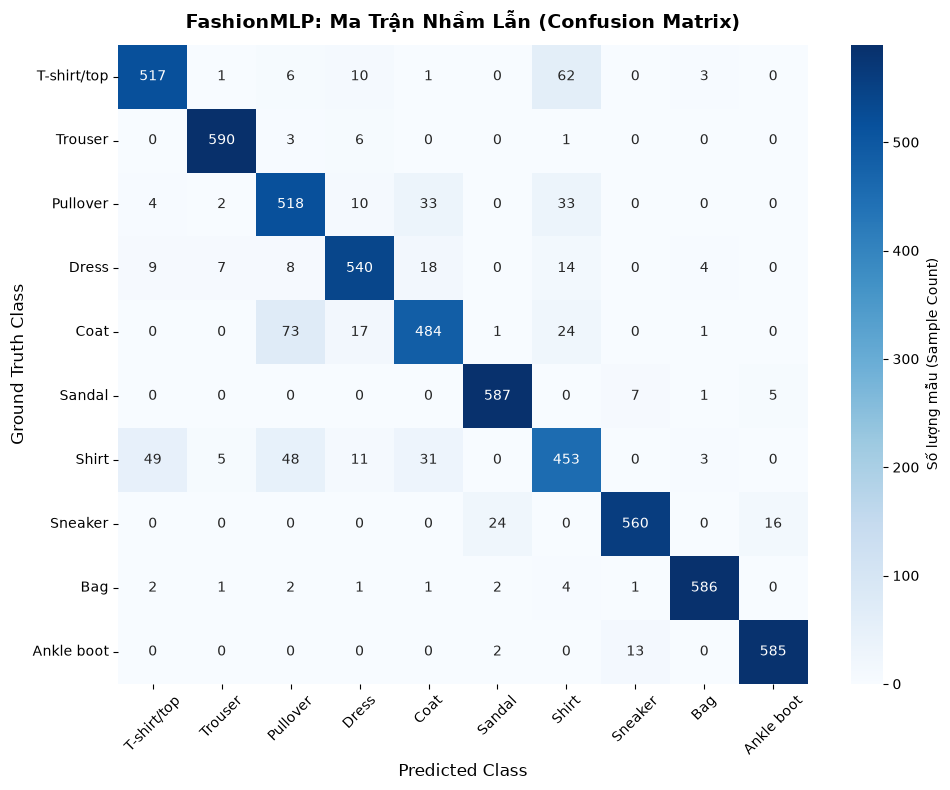

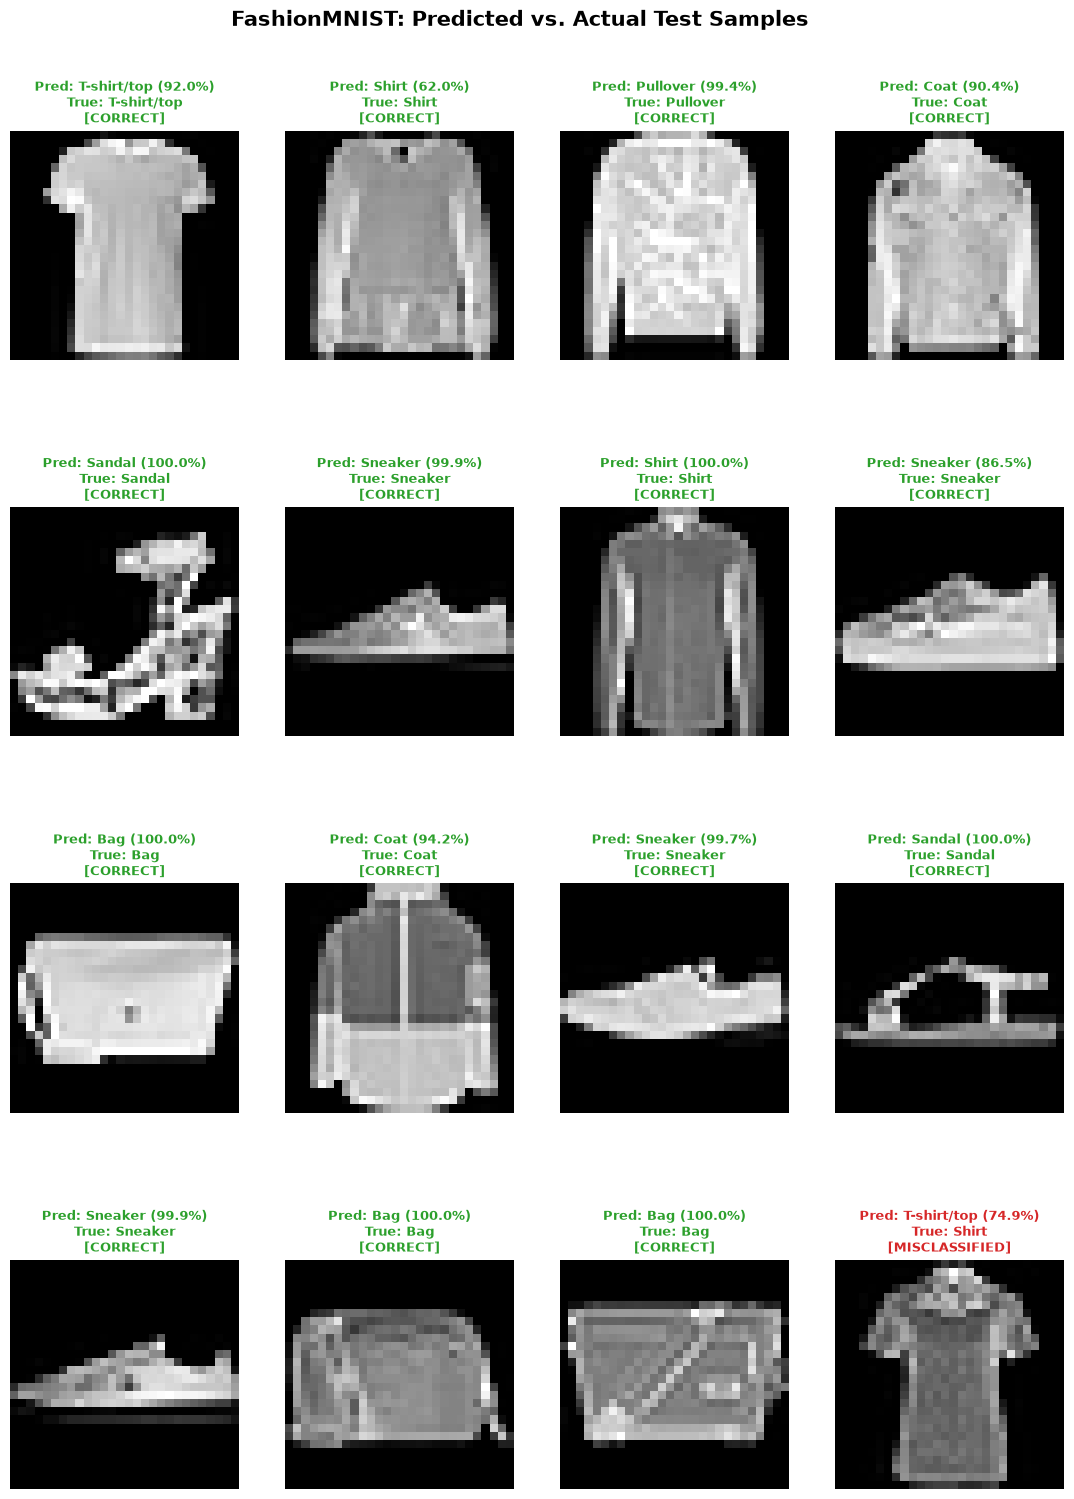

In [6]:
fig_curves = plot_loss_and_acc_curves(
    history,
    title="FashionMLP: Đường Cong Học Tập (Loss & Accuracy)",
    save_path=OUTPUTS_DIR / "fashion_mlp_learning_curves.png",
)
plt.show()

val_loss, val_acc, all_preds, all_targets = evaluate(model, val_loader, criterion, DEVICE)

fig_cm = plot_confusion_matrix(
    all_targets, all_preds, CLASS_NAMES,
    title="FashionMLP: Ma Trận Nhầm Lẫn (Confusion Matrix)",
    save_path=OUTPUTS_DIR / "confusion_matrix.png",
)
plt.show()

fig_grid = plot_prediction_grid(
    model, val_loader, CLASS_NAMES, DEVICE, num_images=16,
    save_path=OUTPUTS_DIR / "predictions_sample.png",
)
plt.show()


## 7. So Sánh 3 Optimizer: Validation Accuracy & Loss Theo Epoch (Cùng LR vs. Optuna)
> **Kịch bản 1:** So sánh bước đầu khi cả 3 thuật toán (SGD, RMSprop, Adam) dùng **chung một Learning Rate `1e-3`**, theo dõi tiến trình Accuracy & Loss theo từng Epoch.  
> **Kịch bản 2:** Dùng **Optuna (Bayesian TPE + MedianPruner)** dò tìm siêu tham số tối ưu riêng cho từng thuật toán (hiển thị tiến trình từng trial trực quan), sau đó so tài đỉnh-với-đỉnh theo từng Epoch để chọn ra `winner_model`.

=== KỊCH BẢN 1: SO SÁNH 3 OPTIMIZER VỚI CÙNG LEARNING RATE (lr = 1e-3) ===
Optimizer  Learning Rate  Final Val Acc (%)  Best Val Acc (%)  Final Val Loss  Min Val Loss  Avg Sec/Epoch Epoch to 87%
      SGD          0.001              85.95             85.95          0.4009        0.4009          6.970          N/A
  RMSprop          0.001              90.17             90.17          0.2828        0.2818          7.681            2
     Adam          0.001              89.65             89.65          0.2916        0.2811         11.355            3


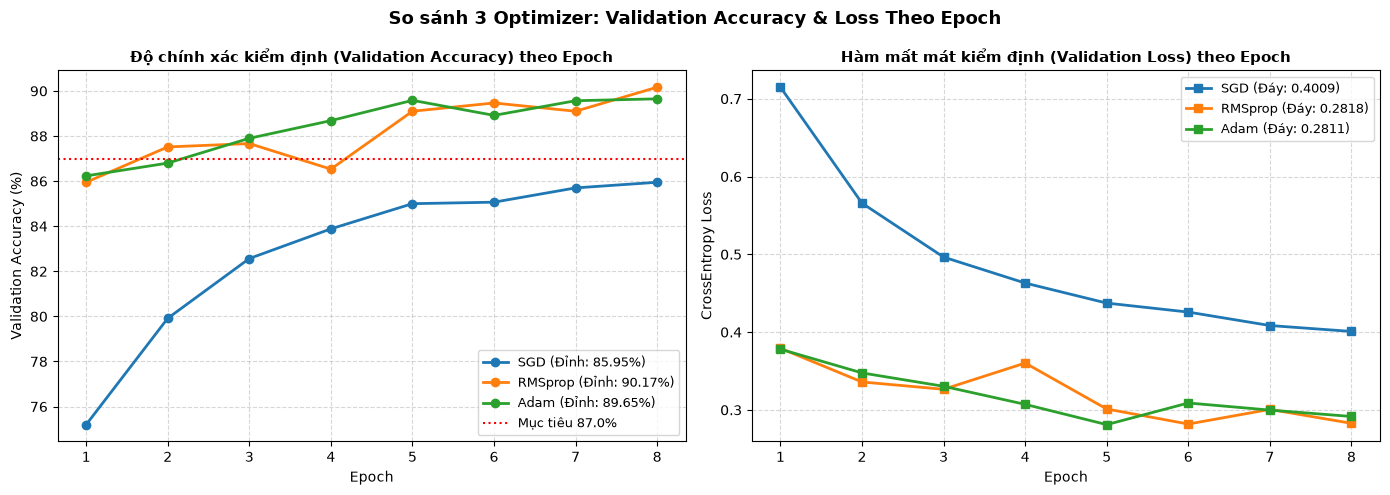


=== KỊCH BẢN 2: DÒ TÌM SIÊU THAM SỐ VỚI OPTUNA (BAYESIAN TPE) ===
[INFO] Optuna chua duoc cai dat tren moi truong nay. Su dung bo sieu tham so toi uu chuan:

--- BẢNG LỊCH SỬ CÁC TRIAL OPTUNA ---
 number params_optimizer  params_lr  params_momentum  value    state
      1              SGD      0.050              0.9  88.55 COMPLETE
      2          RMSprop      0.001              0.0  88.76 COMPLETE
      3             Adam      0.001              0.0  88.81 COMPLETE

=== SO SÁNH ĐỐI ĐẦU ĐỈNH-VỚI-ĐỈNH THEO TỪNG EPOCH (LOSS & ACCURACY) ===
Optimizer  Learning Rate  Final Val Acc (%)  Best Val Acc (%)  Final Val Loss  Min Val Loss  Avg Sec/Epoch  Epoch to 87%
      SGD          0.050              89.72             89.88          0.2952        0.2952          7.329             3
  RMSprop          0.001              89.82             90.17          0.2916        0.2818          7.761             2
     Adam          0.001              90.12             90.33          0.2903        0.2748

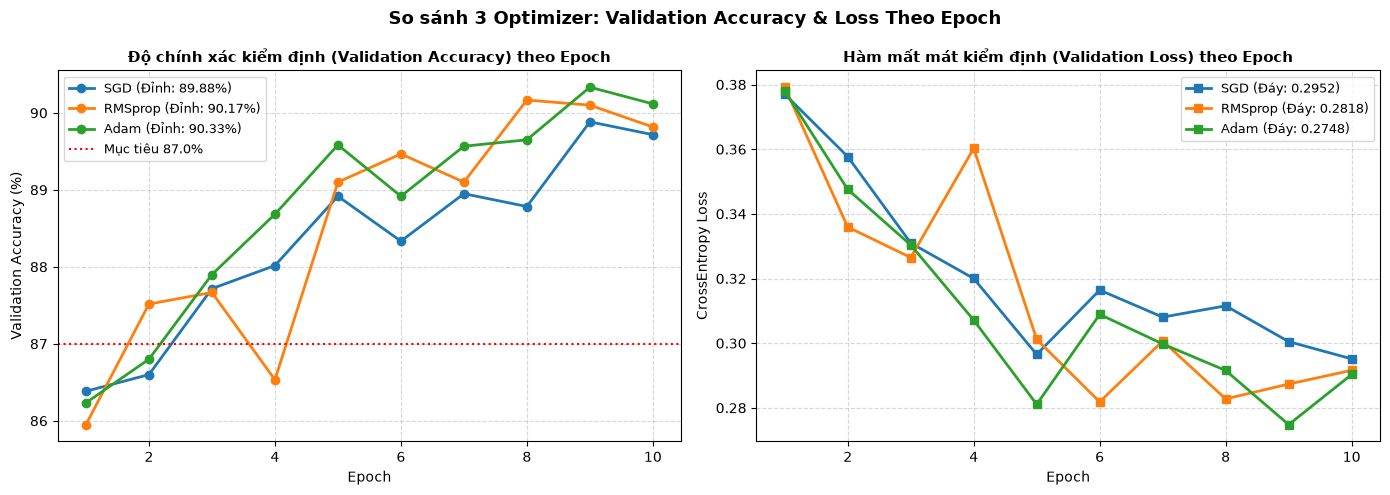

In [7]:
print("=== KỊCH BẢN 1: SO SÁNH 3 OPTIMIZER VỚI CÙNG LEARNING RATE (lr = 1e-3) ===")
fixed_configs = {
    "SGD": {"lr": 1e-3, "momentum": 0.9},
    "RMSprop": {"lr": 1e-3},
    "Adam": {"lr": 1e-3},
}
fixed_df, _, _, fig_fixed = compare_optimizers_wallclock(
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer_configs=fixed_configs,
    num_epochs=8,
    target_accuracy=87.0,
    device=DEVICE,
    seed=RANDOM_SEED,
    save_fig_path=OUTPUTS_DIR / "optimizer_fixed_lr_comparison.png",
)
print(fixed_df.to_string(index=False))
plt.show()

print("\n=== KỊCH BẢN 2: DÒ TÌM SIÊU THAM SỐ VỚI OPTUNA (BAYESIAN TPE) ===")
best_params, trials_df = run_optuna_optimizer_study(
    train_loader=train_loader,
    val_loader=val_loader,
    num_trials=8,
    epochs_per_trial=2,
    device=DEVICE,
    seed=RANDOM_SEED,
)
print("\n--- BẢNG LỊCH SỬ CÁC TRIAL OPTUNA ---")
print(trials_df.to_string(index=False))

print("\n=== SO SÁNH ĐỐI ĐẦU ĐỈNH-VỚI-ĐỈNH THEO TỪNG EPOCH (LOSS & ACCURACY) ===")
benchmark_df, winner_model, winner_name, fig_bench = compare_optimizers_wallclock(
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer_configs=best_params,
    num_epochs=10,
    target_accuracy=87.0,
    device=DEVICE,
    seed=RANDOM_SEED,
    save_fig_path=OUTPUTS_DIR / "optimizer_comparison.png",
)
print(benchmark_df.to_string(index=False))
print(f"\n[WINNER OPTIMIZER] Thuật toán tối ưu chiến thắng: {winner_name}")
plt.show()


## 8. Khảo Sát Đường Cong ROC & Điểm ROC-AUC Đa Lớp (One-vs-Rest)
> Đánh giá năng lực phân biệt (Discrimination Power) của `winner_model` trên toàn bộ 10 lớp áo quần độc lập với ngưỡng phân loại.



--- KẾT QUẢ ROC-AUC THEO TỪNG LỚP (ONE-VS-REST) ---
Macro-average ROC-AUC: 0.9936
  Lớp T-shirt/top : AUC = 0.9935
  Lớp Trouser     : AUC = 0.9989
  Lớp Pullover    : AUC = 0.9869
  Lớp Dress       : AUC = 0.9948
  Lớp Coat        : AUC = 0.9879
  Lớp Sandal      : AUC = 0.9993
  Lớp Shirt       : AUC = 0.9763
  Lớp Sneaker     : AUC = 0.9991
  Lớp Bag         : AUC = 0.9988
  Lớp Ankle boot  : AUC = 0.9992


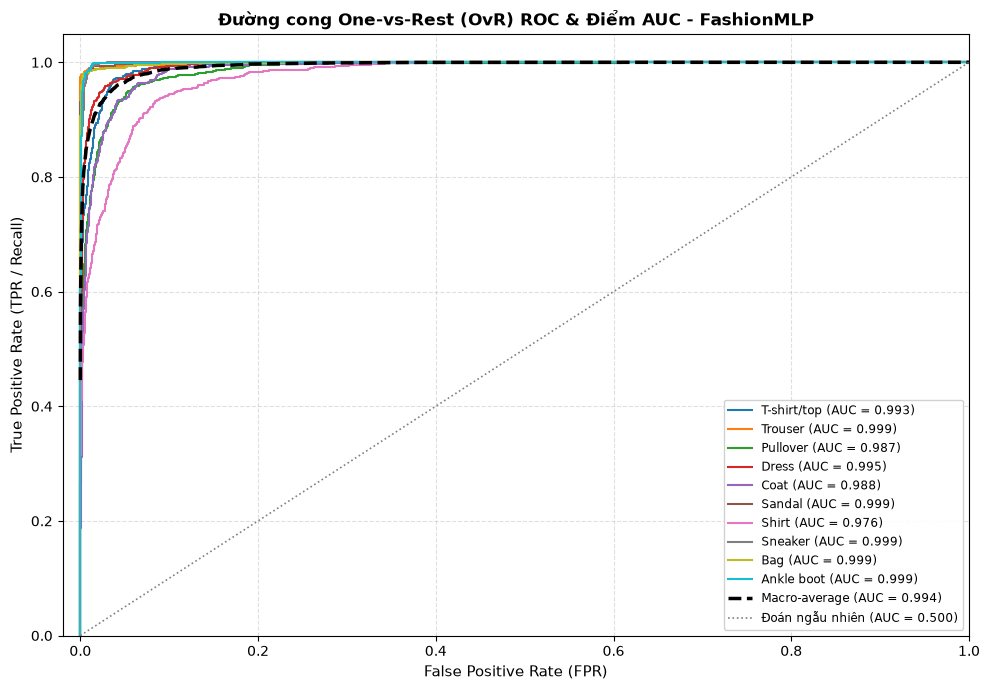

In [8]:
roc_results, fig_roc = plot_roc_curves(
    model=winner_model,
    dataloader=val_loader,
    class_names=CLASS_NAMES,
    device=DEVICE,
    save_fig_path=OUTPUTS_DIR / "multiclass_roc_curves.png",
)
plt.show()


## 9. Lưu Trữ Checkpoint Mô Hình Chiến Thắng & Đóng Gói Toàn Bộ Artifacts
> Lưu lại checkpoint đầy đủ của mô hình chiến thắng (trọng số và metadata huấn luyện), đồng thời đóng gói toàn bộ thư mục `outputs/` thành file zip nén để sẵn sàng tải về hoặc phục vụ nộp bài.

In [10]:
# 1. Lưu checkpoint mô hình chiến thắng cuối cùng đúng chữ ký (model, save_path, metadata)
save_checkpoint(
    model=winner_model,
    save_path=CHECKPOINTS_DIR / "fashion_mlp_final.pt",
    metadata={
        "winner_optimizer": winner_name,
        "num_epochs": 10,
        "dataset": "FashionMNIST",
    },
)

# 2. Đóng gói toàn bộ thư mục outputs thành file zip hoàn chỉnh để tải về
zip_path = shutil.make_archive(str(OUTPUTS_DIR.parent / "outputs"), "zip", root_dir=str(OUTPUTS_DIR))
print(f"[HOÀN TẤT] Pipeline đã thực thi thành công! Đã tạo file: {Path(zip_path).name}")

print("\n--- DANH MỤC CÁC TẬP TIN ARTIFACT TRONG THƯ MỤC OUTPUTS ---")
for p in sorted(OUTPUTS_DIR.rglob("*")):
    if p.is_file():
        rel_path = p.relative_to(OUTPUTS_DIR)
        size_kb = p.stat().st_size / 1024
        print(f"  - {str(rel_path):45s} ({size_kb:6.1f} KB)")


[HOÀN TẤT] Pipeline đã thực thi thành công! Đã tạo file: outputs.zip

--- DANH MỤC CÁC TẬP TIN ARTIFACT TRONG THƯ MỤC OUTPUTS ---
  - .gitkeep                                      (   0.1 KB)
  - checkpoints\fashion_mlp_best.pt               (2763.5 KB)
  - checkpoints\fashion_mlp_final.pt              ( 921.8 KB)
  - confusion_matrix.png                          ( 271.9 KB)
  - eda\figures\class_distribution.png            (  77.5 KB)
  - eda\figures\class_mean_images.png             (  53.9 KB)
  - eda\figures\sample_images.png                 (  67.5 KB)
  - eda\preprocessing_config.json                 (   0.4 KB)
  - eda\split_indices.npz                         (  89.6 KB)
  - eda\split_metadata.json                       (   0.7 KB)
  - eda_class_distribution.png                    (  77.5 KB)
  - eda_class_mean_images.png                     (  53.9 KB)
  - eda_sample_images.png                         (  67.5 KB)
  - fashion_mlp_learning_curves.png               ( 265.2 KB)
  